# Netflix Movies and TV Shows Data Analysis

## Project Overview
This Data Science mini project explores a Netflix titles dataset using Python. It examines content types, release years, countries, ratings, and genres, then creates visualizations and summarizes key findings.

## Objectives
- Work with a real-world dataset.
- Clean and explore the data using Pandas.
- Generate meaningful insights.
- Create visualizations and summarize findings.

## Tools Used
Python, Pandas, NumPy, Matplotlib, Seaborn, Google Colab.


## 1. Load the Dataset

Download `netflix_titles.csv` from a public Kaggle Netflix Movies and TV Shows dataset. When this notebook runs in Google Colab, upload the CSV file when prompted.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from IPython.display import display

sns.set_theme(style="whitegrid")

uploaded = files.upload()  # Select netflix_titles.csv
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())


Saving archive.zip to archive (1).zip
Dataset loaded successfully!
Rows and columns: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 2. Explore the Dataset

Review the column names, data types, missing values, and summary statistics.

In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values by column:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nSummary of numerical columns:")
display(df.describe(include="all").T)


Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

Missing values by column:


,0
director,2634
country,831
cast,825
date_added,10
rating,4
duration,3
show_id,0
type,0
title,0
release_year,0



Summary of numerical columns:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s8807,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Zubaan,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Clean the Data

Remove duplicate rows and prepare useful columns for analysis. Missing values are not automatically filled with invented values; for categorical charts, missing labels are shown as `Unknown`.

In [ ]:
df = df.drop_duplicates().copy()

for col in ["type", "country", "rating", "listed_in", "release_year", "date_added"]:
    if col in df.columns:
        if col in ["type", "country", "rating", "listed_in"]:
            df[col] = df[col].fillna("Unknown")

if "date_added" in df.columns:
    df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")

print("Dataset after removing duplicates:", df.shape)
print("Remaining missing values:")
display(df.isnull().sum().sort_values(ascending=False))


Dataset after removing duplicates: (8807, 12)
Remaining missing values:


,0
director,2634
cast,825
date_added,98
duration,3
title,0
type,0
show_id,0
country,0
release_year,0
rating,0


,Number of titles
type,
Movie,6131
TV Show,2676


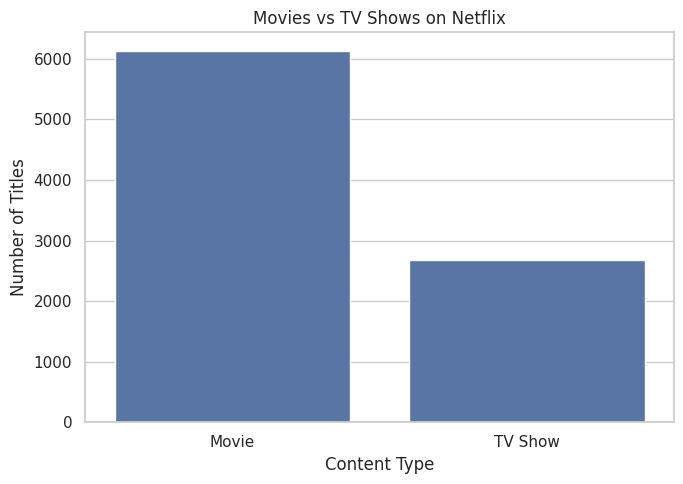

In [ ]:
type_counts = df["type"].value_counts()
display(type_counts.rename("Number of titles").to_frame())

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="type", order=type_counts.index)
plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()


## 4. Analyze Movies and TV Shows

Compare the number of movies and TV shows in the dataset.

## 5. Content Released by Year

This chart shows the number of titles by release year. Very old or missing release years may be absent from the plot.

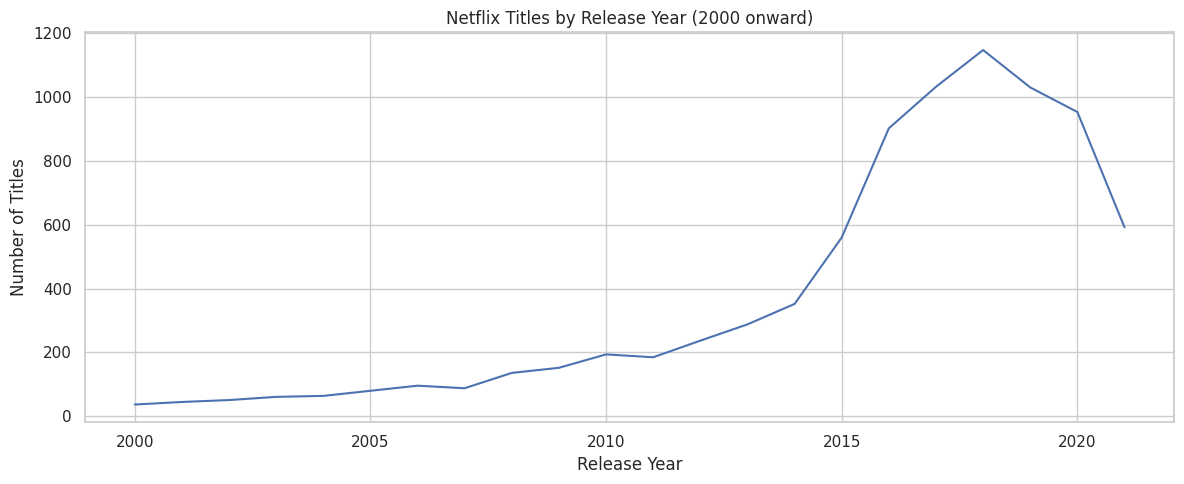

Most common release years:


,Number of titles
release_year,
2018,1147
2017,1032
2019,1030
2020,953
2016,902
2021,592
2015,560
2014,352
2013,288


In [ ]:
if "release_year" in df.columns:
    yearly_counts = df["release_year"].dropna().astype(int).value_counts().sort_index()
    yearly_counts = yearly_counts[yearly_counts.index >= 2000]

    plt.figure(figsize=(12, 5))
    plt.plot(yearly_counts.index, yearly_counts.values)
    plt.title("Netflix Titles by Release Year (2000 onward)")
    plt.xlabel("Release Year")
    plt.ylabel("Number of Titles")
    plt.tight_layout()
    plt.show()

    print("Most common release years:")
    display(df["release_year"].value_counts().head(10).rename("Number of titles").to_frame())


## 6. Top Countries

The `country` column can contain multiple countries in one cell. Split those values so each country can be counted separately.

,Number of titles
country,
United States,3689
India,1046
United Kingdom,804
Canada,445
France,393
Japan,318
Spain,232
South Korea,231
Germany,226


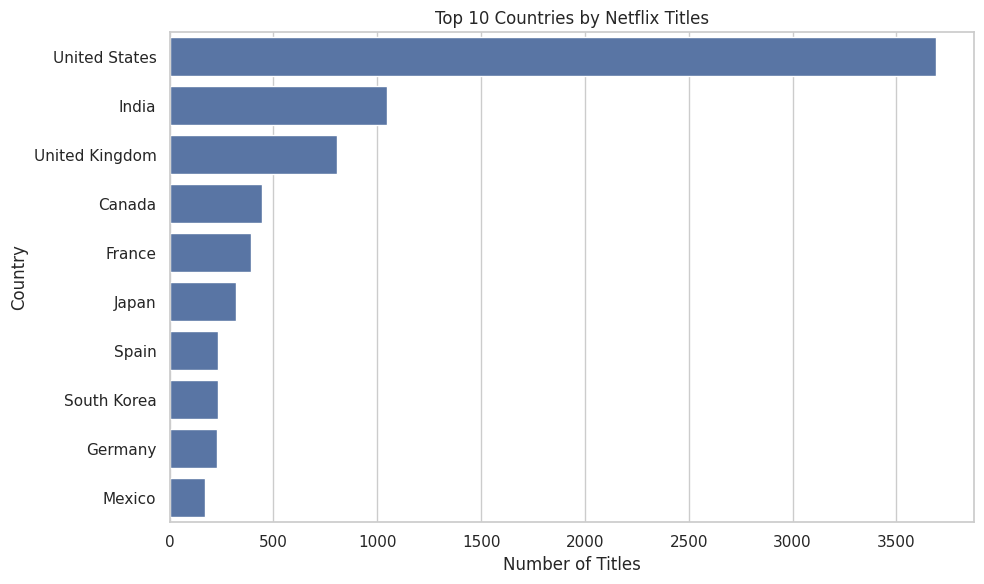

In [ ]:
if "country" in df.columns:
    countries = (
        df.loc[df["country"].ne("Unknown"), "country"]
        .dropna()
        .str.split(", ")
        .explode()
    )
    top_countries = countries.value_counts().head(10)
    display(top_countries.rename("Number of titles").to_frame())

    plt.figure(figsize=(10, 6))
    sns.barplot(x=top_countries.values, y=top_countries.index)
    plt.title("Top 10 Countries by Netflix Titles")
    plt.xlabel("Number of Titles")
    plt.ylabel("Country")
    plt.tight_layout()
    plt.show()


## 7. Most Common Genres

Titles may belong to more than one genre, so split the genre list before counting.

,Number of titles
listed_in,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641


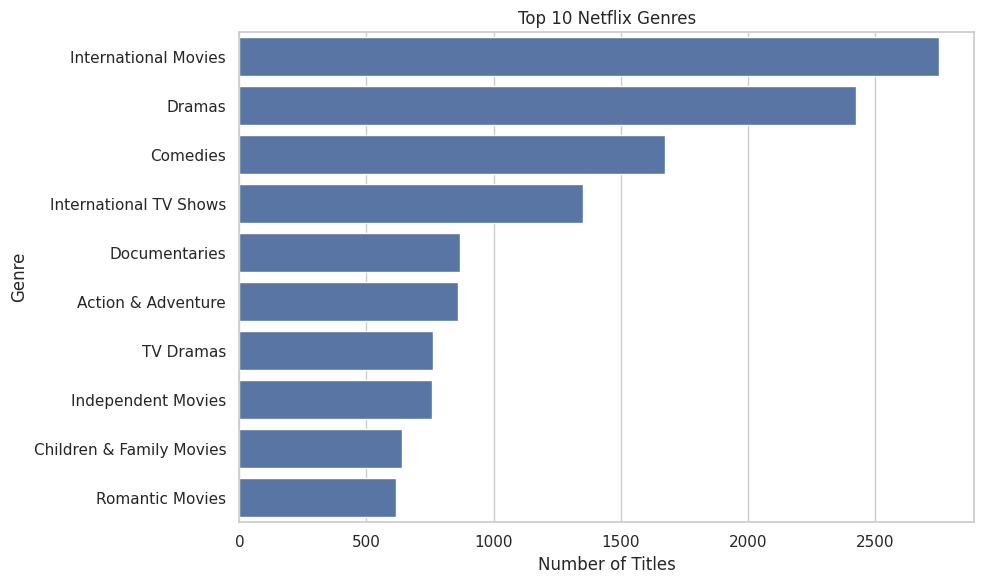

In [ ]:
if "listed_in" in df.columns:
    genres = (
        df.loc[df["listed_in"].ne("Unknown"), "listed_in"]
        .dropna()
        .str.split(", ")
        .explode()
    )
    top_genres = genres.value_counts().head(10)
    display(top_genres.rename("Number of titles").to_frame())

    plt.figure(figsize=(10, 6))
    sns.barplot(x=top_genres.values, y=top_genres.index)
    plt.title("Top 10 Netflix Genres")
    plt.xlabel("Number of Titles")
    plt.ylabel("Genre")
    plt.tight_layout()
    plt.show()


## 8. Ratings Distribution

Explore the content ratings recorded in the dataset.

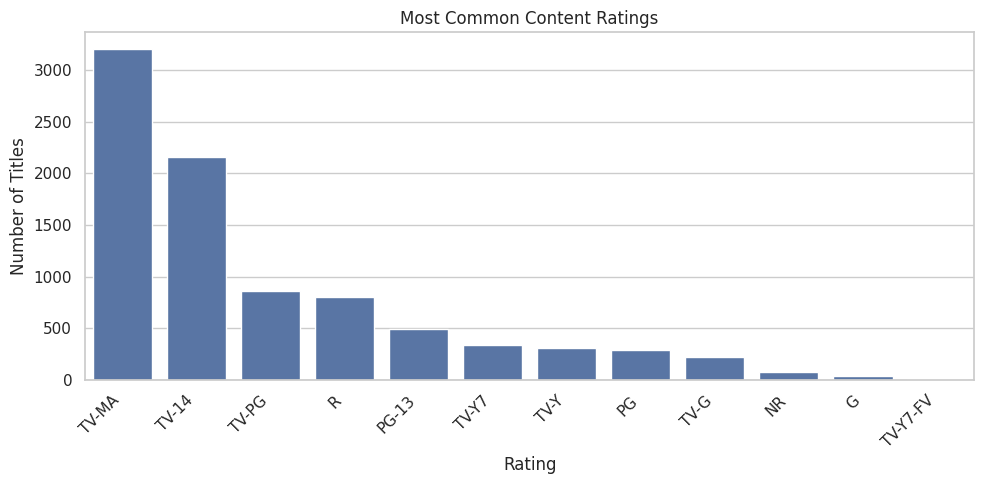

,Number of titles
rating,
TV-MA,3207
TV-14,2160
TV-PG,863
R,799
PG-13,490
TV-Y7,334
TV-Y,307
PG,287
TV-G,220


In [ ]:
if "rating" in df.columns:
    rating_counts = df["rating"].value_counts().head(12)

    plt.figure(figsize=(10, 5))
    sns.barplot(x=rating_counts.index, y=rating_counts.values)
    plt.title("Most Common Content Ratings")
    plt.xlabel("Rating")
    plt.ylabel("Number of Titles")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    display(rating_counts.rename("Number of titles").to_frame())


## 9. Key Findings

Run the following cell to generate a short summary from the dataset you uploaded. The results depend on the version of the dataset.

In [ ]:
print("KEY FINDINGS")
print("-" * 40)

print(f"Total titles: {len(df):,}")

if "type" in df.columns and not df["type"].empty:
    print(f"Most common content type: {df['type'].value_counts().idxmax()}")

if "release_year" in df.columns and df["release_year"].notna().any():
    print(f"Most common release year: {int(df['release_year'].mode().iloc[0])}")

if "country" in df.columns:
    valid_countries = df.loc[df["country"].ne("Unknown"), "country"].dropna().str.split(", ").explode()
    if not valid_countries.empty:
        print(f"Country appearing most often: {valid_countries.value_counts().idxmax()}")

if "listed_in" in df.columns:
    valid_genres = df.loc[df["listed_in"].ne("Unknown"), "listed_in"].dropna().str.split(", ").explode()
    if not valid_genres.empty:
        print(f"Most common genre: {valid_genres.value_counts().idxmax()}")

print("\nNote: These are descriptive patterns in this dataset, not evidence of cause and effect.")


KEY FINDINGS
----------------------------------------
Total titles: 8,807
Most common content type: Movie
Most common release year: 2018
Country appearing most often: United States
Most common genre: International Movies

Note: These are descriptive patterns in this dataset, not evidence of cause and effect.


## 10. Conclusion

This project demonstrates how Python can be used to load, clean, explore, and visualize a real-world dataset. The charts and summary help identify patterns in Netflix content types, release years, countries, genres, and ratings.

### Dataset Source
Use a public Netflix Movies and TV Shows dataset from Kaggle.Dataset Link: https://www.kaggle.com/datasets/shivamb/netflix-shows.

### Project Repository
Add your GitHub repository link here after uploading this notebook.
